# 機械翻訳の自動評価 (BLEU) と対訳コーパスのノイズフィルタリング

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_bleu_corpus.ipynb)

書籍 第4章「言語生成問題の解き方」（4-2-4 評価・図 4.11、4-2-5 コーパス）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、BLEU の定義式実装・マルチリファレンス評価・表層一致評価の限界から、コンパラブルコーパス・Web 対訳からの文アライメント信頼度とノイズフィルタリングまでを体験します。

1. **BLEU の定義式実装（クリッピング・簡潔性ペナルティ）と `sacrebleu` との一致確認**（4-2-4、p.153）
2. **図 4.11 (p.154) の再現**：シングルリファレンス vs マルチリファレンス BLEU-2、および文単位 BLEU（脚注 43）
3. **表層一致に基づく評価尺度の限界**（言い換え・語順・否定反転）
4. **コンパラブルコーパス・Web 対訳からの文アライメント信頼度とノイズフィルタリング**（4-2-5、p.157〜158）

（※ 翻訳メモリ・IBM Model 1・フレーズベース SMT については [`ch4_smt.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_smt.ipynb) を、参照訳なしの品質推定については [`ch1_qe.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb) を参照してください。）

In [1]:
!pip install -q sacrebleu

In [2]:
import math
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu

## 1. BLEU の定義式実装と検証（4-2-4、p.153）

機械翻訳の自動評価で広く使われる **BLEU** は、次の 2 要素の積で定義されます（書籍 p.153、$N$ は通常 4）。

$$\mathrm{BLEU} = \mathrm{BP} \times \exp\left(\sum_{n=1}^{N} w_n \log(p_n)\right), \quad \mathrm{BP} = \begin{cases} 1 & (c > r) \\ \exp(1 - r/c) & (c \le r) \end{cases}$$

（※ 書籍第 1 刷 p.153 では指数関数の中身が誤って逆数 `1 / ...` として記載されています（[正誤表](https://github.com/mamorlis/nlpbook/blob/main/errata.md)）。本ノートブックでは正しい定義式を実装し、`sacrebleu` と一致することを確認します。）

In [3]:
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

def compute_bleu(hypotheses, references_list, max_n=4):
    """コーパスレベル BLEU（複数リファレンス対応、smooth_method='none' 相当）"""
    clipped_counts = [0] * max_n
    total_counts = [0] * max_n
    hyp_len = 0
    ref_len = 0

    for idx, hyp in enumerate(hypotheses):
        h_tok = hyp.split()
        hyp_len += len(h_tok)
        refs_tok = [refs[idx].split() for refs in references_list]
        # 出力長に最も近い参照訳長を代表値 r とする
        ref_len += min((len(rt) for rt in refs_tok), key=lambda l: (abs(l - len(h_tok)), l))

        for n in range(1, max_n + 1):
            h_ng = Counter(ngrams(h_tok, n))
            max_r_ng = Counter()
            for rt in refs_tok:
                r_ng = Counter(ngrams(rt, n))
                for ng, cnt in r_ng.items():
                    if cnt > max_r_ng[ng]:
                        max_r_ng[ng] = cnt
            clipped_counts[n - 1] += sum(min(cnt, max_r_ng[ng]) for ng, cnt in h_ng.items())
            total_counts[n - 1] += sum(h_ng.values())

    precisions = [c / t if t > 0 else 0.0 for c, t in zip(clipped_counts, total_counts)]
    bp = 1.0 if hyp_len > ref_len else math.exp(1.0 - ref_len / hyp_len)
    if min(precisions) == 0.0:
        bleu = 0.0
    else:
        bleu = bp * math.exp(sum(math.log(p) for p in precisions) / max_n)
    return bleu * 100.0, [p * 100.0 for p in precisions], bp

refs = [
    "the cat is on the mat",
    "there is a cat on the mat",
]
hyps = [
    "the cat is on the mat",
    "there is a dog on the mat",
]

my_bleu, precs, bp = compute_bleu(hyps, [refs], max_n=4)
lib_bleu = sacrebleu.corpus_bleu(hyps, [refs], tokenize="none", smooth_method="none")
print(f"手計算 BLEU   = {my_bleu:.4f} (n-gram 適合率={[round(p, 2) for p in precs]}, BP={bp:.4f})")
print(f"sacrebleu     = {lib_bleu.score:.4f}")

手計算 BLEU   = 68.1561 (n-gram 適合率=[92.31, 81.82, 66.67, 42.86], BP=1.0000)
sacrebleu     = 68.1561


### クリッピングと簡潔性ペナルティの働きを確認する

In [4]:
ref_sample = ["the cat is on the mat"]
cases = [
    ("適切な翻訳（完全一致）", ["the cat is on the mat"]),
    ("同じ語を連呼（クリッピングの検証）", ["the the the the the the"]),
    ("極端に短い出力（BP の検証）", ["the cat"]),
]

for label, h in cases:
    b_none = sacrebleu.corpus_bleu(h, [ref_sample], tokenize="none", smooth_method="none")
    b_exp = sacrebleu.corpus_bleu(h, [ref_sample], tokenize="none", smooth_method="exp")
    print(f"{label:32s} | BLEU(none)={b_none.score:6.2f}, BLEU(smooth)={b_exp.score:6.2f}, BP={b_none.bp:.3f}, p1={b_none.precisions[0]:.1f}")

適切な翻訳（完全一致）                      | BLEU(none)=100.00, BLEU(smooth)=100.00, BP=1.000, p1=100.0
同じ語を連呼（クリッピングの検証）                | BLEU(none)=  0.00, BLEU(smooth)=  9.65, BP=1.000, p1=33.3
極端に短い出力（BP の検証）                  | BLEU(none)=  0.00, BLEU(smooth)=  0.00, BP=0.135, p1=100.0


- `"the the the the the the"` は 6 単語すべてが参照文の `"the"` と一致するため、クリッピングなしでは 1-gram 適合率が 100% になってしまいますが、クリッピングにより参照文中の出現回数（2回）までに制限され、`p1 = 33.3`、2-gram 以降は 0 のため BLEU は低くなります。
- `"the cat"` は 1-gram・2-gram 適合率が 100% ですが、文長が短すぎるため `BP = 0.135` と強いペナルティが掛かります。

---

## 2. 図 4.11 (p.154) の再現：シングルリファレンス vs マルチリファレンスと文単位 BLEU

書籍 p.153〜154 では、同じ出力に対して **参照訳（リファレンス）を増やすと BLEU スコアが大きく上がる** 例（図 4.11：`BLEU-2 = 0.38` → `0.71`）と、元々の BLEU は**コーパス単位で測ることを前提としており、文単位 (`sentenceBLEU`) では不安定になりやすい**注意点（脚注 43）が解説されています。

In [5]:
# 書籍 p.154 の記述に合わせた 8 単語出力と 2 つの参照訳
# 共通バイグラム: "it is", "like a", "language to", "to me"
hyp_411 = ["it is like a new language to me"]
ref1_411 = ["yes it is one difficult language to study"]
ref2_411 = ["actually that seems like a good topic to me"]

bleu2_single, p_single, bp_single = compute_bleu(hyp_411, [ref1_411], max_n=2)
bleu2_multi, p_multi, bp_multi = compute_bleu(hyp_411, [ref1_411, ref2_411], max_n=2)

print("=== 書籍 図 4.11（BLEU-2）の比較 ===")
print(f"シングルリファレンス : p1={p_single[0]/100:.2f}, p2={p_single[1]/100:.2f}, BP={bp_single:.2f}, BLEU-2={bleu2_single/100:.2f}")
print(f"マルチリファレンス   : p1={p_multi[0]/100:.2f}, p2={p_multi[1]/100:.2f}, BP={bp_multi:.2f}, BLEU-2={bleu2_multi/100:.2f}")

# 文単位 (sentence_bleu) とコーパス単位でのスムージング有無の違い
s1 = sacrebleu.sentence_bleu(hyp_411[0], [ref1_411[0]]).score
s2 = sacrebleu.sentence_bleu(hyp_411[0], [ref1_411[0], ref2_411[0]]).score
print(f"\n[参考: 4-gram sentenceBLEU (sacrebleu)] single={s1:.2f}, multi={s2:.2f}")

=== 書籍 図 4.11（BLEU-2）の比較 ===
シングルリファレンス : p1=0.50, p2=0.29, BP=1.00, BLEU-2=0.38
マルチリファレンス   : p1=0.88, p2=0.57, BP=1.00, BLEU-2=0.71

[参考: 4-gram sentenceBLEU (sacrebleu)] single=15.62, multi=21.36


同じ出力文・同じモデルでも、参照訳の数や評価設定を変えるだけでスコアは大きく変わります（書籍 p.153 脚注 42：「違う設定での BLEU スコアの絶対値の比較には意味がない」）。

> **日本語テキストを `sacrebleu` で評価する場合**: 分かち書き済みのコーパスでは `tokenize="none"` を使いますが、通常の未分割日本語文では `sacrebleu --tokenize ja-mecab` のように日本語向けトークナイザを指定する必要があります（[`ch4_eole.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_eole.ipynb) も参照）。

---

## 3. 表層一致に基づく評価尺度の限界

BLEU は高速で再現性が高い一方、**表層的な n-gram の一致**しか見ないため、言い換えや否定語の有無に対して直感とズレることがあります。

In [6]:
ref_en = ["I bought a new book at the bookstore yesterday"]
examples = [
    ("参照文と同一", "I bought a new book at the bookstore yesterday"),
    ("意味は同じ（言い換え）", "Yesterday I purchased a brand new book from the shop"),
    ("語順を崩した非流暢な文", "yesterday book new a bought I bookstore the at"),
    ("否定が逆（意味は真逆）", "I did not buy a new book at the bookstore yesterday"),
]

eval_rows = []
for desc, hyp in examples:
    res = sacrebleu.corpus_bleu([hyp], [ref_en], tokenize="none")
    eval_rows.append({
        "ケース": desc,
        "出力文": hyp,
        "BLEU": round(res.score, 2),
        "1-gram": round(res.precisions[0], 1),
        "4-gram": round(res.precisions[3], 1),
    })

pd.DataFrame(eval_rows)

,ケース,出力文,BLEU,1-gram,4-gram
0,参照文と同一,I bought a new book at the bookstore yesterday,100.00,100.0,100.0
1,意味は同じ（言い換え）,Yesterday I purchased a brand new book from th...,10.55,50.0,3.6
2,語順を崩した非流暢な文,yesterday book new a bought I bookstore the at,8.26,100.0,2.1
3,否定が逆（意味は真逆）,I did not buy a new book at the bookstore yest...,59.00,72.7,50.0


- **言い換えに厳しい**: 意味がほぼ同じでも異なる単語（`bought` → `purchased`、`bookstore` → `shop`）を使うと BLEU が大きく下がります。
- **否定や重要語の反転に鈍感**: `"not"` を 1 語足して意味が真逆になっても、多くの n-gram が一致するため高い BLEU がついてしまいます。

この限界を補うアプローチとして、第 1 章の[品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)（COMET-QE 等）があります。

---

## 4. コンパラブルコーパス・Web 対訳からの文アライメント信頼度とノイズフィルタリング (4-2-5)

書籍 4-2-5「コーパス」（p.157〜158）では、Web クロール対訳 (JParaCrawl) やコンパラブルコーパス（ASPEC・NTCIR 等）を活用する際、**文アライメントの誤対応や極端な長さ不均衡・未翻訳文などのノイズを取り除く品質フィルタリング**が不可欠であることが解説されています。

クリーンな英日対訳（24 文）を用意した上で、実務の Web 収集・コンパラブルコーパスで頻出する **4 種類のノイズ対（計 10 文）** を混ぜた **34 文のノイジーコーパス** を作成し、次の 3 条件でフィルタリングします。

1. **単語数・文字数長比フィルタ**: 単語長比 $\le 2.5$ かつ文字長比 $\le 3.5$（極端な欠落・過剰ペアを除去）
2. **日本語文字率・数値一致性フィルタ**: 目的言語側の日本語文字（ひらがな・カタカナ・漢字）率 $\ge 0.35$、および英日双方のアラビア数値集合が一致（未翻訳・年号/数値食い違いを除去）
3. **双方向 IBM Model 1 語彙翻訳信頼度スコア**: IBM Model 1 の EM 学習関数（`train_ibm_model1`、詳細は [`ch4_smt.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_smt.ipynb) 第 2 節参照）を英→日・日→英の両方向で実行し、各文対の双方向 Viterbi 対訳確率の幾何平均スコアを算出して閾値未満（誤対応ペア）を除去

In [7]:
parallel_corpus = [
    (["i", "like", "cats"], ["私", "は", "猫", "が", "好き"]),
    (["i", "like", "dogs"], ["私", "は", "犬", "が", "好き"]),
    (["she", "likes", "music"], ["彼女", "は", "音楽", "が", "好き"]),
    (["he", "likes", "books"], ["彼", "は", "本", "が", "好き"]),
    (["i", "read", "books"], ["私", "は", "本", "を", "読む"]),
    (["i", "read", "a", "book"], ["私", "は", "本", "を", "読む"]),
    (["she", "reads", "a", "book"], ["彼女", "は", "本", "を", "読む"]),
    (["he", "writes", "a", "book"], ["彼", "は", "本", "を", "書く"]),
    (["big", "book"], ["大きな", "本"]),
    (["small", "book"], ["小さな", "本"]),
    (["big", "cats", "run"], ["大きな", "猫", "が", "走る"]),
    (["big", "dogs", "run"], ["大きな", "犬", "が", "走る"]),
    (["small", "cats", "sleep"], ["小さな", "猫", "が", "眠る"]),
    (["small", "dogs", "sleep"], ["小さな", "犬", "が", "眠る"]),
    (["dogs", "sleep"], ["犬", "が", "眠る"]),
    (["i", "see", "big", "cats"], ["私", "は", "大きな", "猫", "を", "見る"]),
]

def train_ibm_model1(pairs, n_iter=20):
    en_vocab = {"<NULL>"} | {w for en, _ in pairs for w in en}
    ja_vocab = {w for _, ja in pairs for w in ja}
    # 初期値は一様分布
    t = defaultdict(lambda: 1.0 / len(ja_vocab))

    for _ in range(n_iter):
        count = defaultdict(float)
        total = defaultdict(float)
        for en, ja in pairs:
            en_with_null = ["<NULL>"] + en
            for f in ja:
                z = sum(t[(f, e)] for e in en_with_null)
                for e in en_with_null:
                    c = t[(f, e)] / z
                    count[(f, e)] += c
                    total[e] += c
        for (f, e), val in count.items():
            t[(f, e)] = val / total[e]
    return t

# 1. クリーン対訳 (24 文) + 4 種のノイズ (10 文) = ノイジーコーパス (34 文)
clean_corpus_24 = list(parallel_corpus) + [
    (["she", "sees", "small", "dogs"], ["彼女", "は", "小さな", "犬", "を", "見る"]),
    (["he", "reads", "3", "books", "in", "2024"], ["彼", "は", "2024", "年", "に", "3", "冊", "の", "本", "を", "読む"]),
    (["i", "wrote", "2", "books", "in", "2023"], ["私", "は", "2023", "年", "に", "2", "冊", "の", "本", "を", "書く"]),
    (["cats", "and", "dogs", "run"], ["猫", "と", "犬", "が", "走る"]),
    (["students", "study", "music"], ["学生", "は", "音楽", "を", "学ぶ"]),
    (["students", "read", "books"], ["学生", "は", "本", "を", "読む"]),
    (["she", "writes", "music"], ["彼女", "は", "音楽", "を", "書く"]),
    (["i", "see", "2", "small", "cats"], ["私", "は", "2", "匹", "の", "小さな", "猫", "を", "見る"]),
]

noisy_pairs_10 = [
    # ① コンパラブルコーパスからの別文誤対応 (3 文)
    (["i", "like", "cats"], ["彼", "は", "本", "を", "書く"], "誤対応ノイズ"),
    (["big", "dogs", "run"], ["彼女", "は", "音楽", "が", "好き"], "誤対応ノイズ"),
    (["students", "study", "music"], ["小さな", "猫", "が", "眠る"], "誤対応ノイズ"),
    # ② 片側が極端に短い/長い欠落ペア (3 文)
    (["i", "read", "many", "big", "books", "and", "write", "notes", "in", "2024"], ["本"], "長比ノイズ"),
    (["run"], ["私", "は", "大きな", "犬", "と", "小さな", "猫", "が", "好き", "で", "よく", "走る"], "長比ノイズ"),
    (["she", "reads", "a", "big", "book", "with", "students", "today"], ["読む"], "長比ノイズ"),
    # ③ 年号や数値の食い違いペア (2 文)
    (["i", "read", "3", "books", "in", "2024"], ["私", "は", "2019", "年", "に", "5", "冊", "の", "本", "を", "読む"], "数値不一致ノイズ"),
    (["2", "dogs", "sleep"], ["4", "匹", "の", "犬", "が", "眠る"], "数値不一致ノイズ"),
    # ④ 未翻訳の英語混入ペア (2 文)
    (["i", "like", "music", "and", "books"], ["i", "like", "music", "and", "books"], "未翻訳ノイズ"),
    (["big", "cats", "sleep"], ["big", "cats", "が", "sleep"], "未翻訳ノイズ"),
]

noisy_corpus_34 = [(en, ja, "クリーン") for en, ja in clean_corpus_24] + noisy_pairs_10
all_pairs_34 = [(en, ja) for en, ja, _ in noisy_corpus_34]

# 2. 双方向 IBM Model 1 の学習（フィルタ前 34 文）
t_e2j_noisy = train_ibm_model1(all_pairs_34, n_iter=20)
t_j2e_noisy = train_ibm_model1([(ja, en) for en, ja in all_pairs_34], n_iter=20)

def ibm1_bidir_confidence(en, ja, t_e2j, t_j2e):
    en_n = ["<NULL>"] + en
    ja_n = ["<NULL>"] + ja
    s_e2j = np.mean([math.log(max(max(t_e2j[(f, e)] for e in en_n), 1e-12)) for f in ja])
    s_j2e = np.mean([math.log(max(max(t_j2e[(e, f)] for f in ja_n), 1e-12)) for e in en])
    return math.exp(0.5 * (s_e2j + s_j2e))

def ja_script_ratio(ja_tokens):
    joined = "".join(ja_tokens)
    if not joined:
        return 0.0
    return len(re.findall(r"[ぁ-んァ-ヴー一-龥]", joined)) / len(joined)

def extract_numbers(tokens):
    return sorted(re.findall(r"\d+", " ".join(tokens)))

# 3. フィルタリング判定
TAU_IBM1 = 0.32
filter_logs = []
filtered_clean_pairs = []

for idx, (en, ja, kind) in enumerate(noisy_corpus_34):
    tok_ratio = max(len(en) / max(len(ja), 1), len(ja) / max(len(en), 1))
    char_en = max(len("".join(en)), 1)
    char_ja = max(len("".join(ja)), 1)
    char_ratio = max(char_en / char_ja, char_ja / char_en)
    j_ratio = ja_script_ratio(ja)
    num_match = extract_numbers(en) == extract_numbers(ja)
    ibm_score = ibm1_bidir_confidence(en, ja, t_e2j_noisy, t_j2e_noisy)

    reasons = []
    if tok_ratio > 2.5 or char_ratio > 3.5:
        reasons.append(f"長比(語比={tok_ratio:.1f})")
    if j_ratio < 0.35:
        reasons.append(f"日本語率({j_ratio:.2f})")
    if not num_match:
        reasons.append("数値不一致")
    if ibm_score < TAU_IBM1:
        reasons.append(f"双方向IBM1({ibm_score:.3f})")

    keep = len(reasons) == 0
    if keep:
        filtered_clean_pairs.append((en, ja))
    filter_logs.append({
        "ID": idx,
        "元カテゴリ": kind,
        "語長比": round(tok_ratio, 2),
        "日本語率": round(j_ratio, 2),
        "数値一致": num_match,
        "双方向IBM1": round(ibm_score, 3),
        "判定": "採用" if keep else "除外",
        "除外理由": ", ".join(reasons) if reasons else "-",
        "英語文": " ".join(en),
        "日本語文": " ".join(ja),
    })

df_flt = pd.DataFrame(filter_logs)
n_clean_kept = int(((df_flt["元カテゴリ"] == "クリーン") & (df_flt["判定"] == "採用")).sum())
n_noise_drop = int(((df_flt["元カテゴリ"] != "クリーン") & (df_flt["判定"] == "除外")).sum())
print(f"総文対数: {len(df_flt)} -> 採用: {len(filtered_clean_pairs)} 文対 "
      f"(クリーン保持: {n_clean_kept}/24, ノイズ除去: {n_noise_drop}/10)")

print("\n=== 除外されたノイズ文対 (10 文) と除外条件 ===")
display(df_flt[df_flt["判定"] == "除外"][["ID", "元カテゴリ", "語長比", "日本語率", "数値一致", "双方向IBM1", "除外理由", "英語文", "日本語文"]])

総文対数: 34 -> 採用: 24 文対 (クリーン保持: 24/24, ノイズ除去: 10/10)

=== 除外されたノイズ文対 (10 文) と除外条件 ===


,ID,元カテゴリ,語長比,日本語率,数値一致,双方向IBM1,除外理由,英語文,日本語文
24,24,誤対応ノイズ,1.67,1.00,True,0.253,双方向IBM1(0.253),i like cats,彼 は 本 を 書く
25,25,誤対応ノイズ,1.67,1.00,True,0.274,双方向IBM1(0.274),big dogs run,彼女 は 音楽 が 好き
26,26,誤対応ノイズ,1.33,1.00,True,0.183,双方向IBM1(0.183),students study music,小さな 猫 が 眠る
27,27,長比ノイズ,10.00,1.00,False,0.350,"長比(語比=10.0), 数値不一致",i read many big books and write notes in 2024,本
28,28,長比ノイズ,12.00,1.00,True,0.344,長比(語比=12.0),run,私 は 大きな 犬 と 小さな 猫 が 好き で よく 走る
29,29,長比ノイズ,8.00,1.00,True,0.433,長比(語比=8.0),she reads a big book with students today,読む
30,30,数値不一致ノイズ,1.83,0.67,False,0.391,数値不一致,i read 3 books in 2024,私 は 2019 年 に 5 冊 の 本 を 読む
31,31,数値不一致ノイズ,2.00,0.86,False,0.565,数値不一致,2 dogs sleep,4 匹 の 犬 が 眠る
32,32,未翻訳ノイズ,1.00,0.00,True,0.188,"日本語率(0.00), 双方向IBM1(0.188)",i like music and books,i like music and books
33,33,未翻訳ノイズ,1.33,0.08,True,0.196,"日本語率(0.08), 双方向IBM1(0.196)",big cats sleep,big cats が sleep


### フィルタリング前後の IBM Model 1 学習品質と単語アライメント精度比較

ノイズを含むまま学習した IBM Model 1（34 文）と、フィルタリング後のクリーンコーパスから再学習した IBM Model 1（24 文）について、代表語の語彙翻訳確率 $t(f \mid e)$ と、評価用 6 文での単語アライメント Precision / Recall / F1 を比較します。

=== 代表語の語彙翻訳確率 t(f | e) の変化 ===


,英単語 e,フィルタ前 上位訳 (34文),フィルタ後 上位訳 (24文)
0,cats,"猫 (0.74), が (0.24)","猫 (0.89), が (0.11)"
1,dogs,"犬 (0.67), が (0.32)","犬 (0.80), が (0.20)"
2,2024,"の (0.22), 2019 (0.14)","2024 (0.25), 3 (0.25)"
3,3,"の (0.22), 2019 (0.14)","2024 (0.25), 3 (0.25)"
4,music,"音楽 (0.68), が (0.06)","音楽 (0.87), は (0.11)"
5,study,"学ぶ (0.25), 眠る (0.25)","学ぶ (0.73), を (0.22)"
6,run,"走る (0.28), 好き (0.13)","走る (0.61), が (0.39)"



=== テスト 6 文での単語アライメント評価比較 ===


,条件,Precision,Recall,F1,誤アライメント(FP),見逃し(FN)
0,フィルタ前 (ノイジー 34文),0.857,0.783,0.818,3,5
1,フィルタ後 (クリーン 24文),0.864,0.826,0.844,3,4


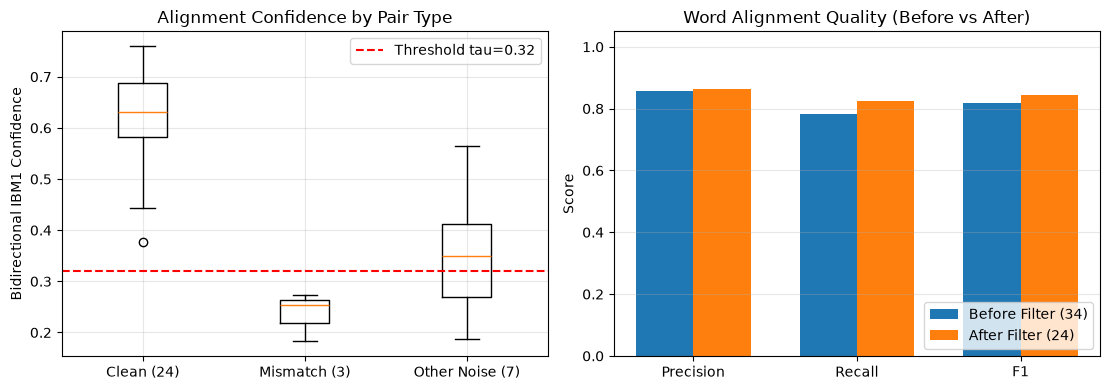

In [8]:
# フィルタ後データで IBM Model 1 を再学習
t_e2j_clean = train_ibm_model1(filtered_clean_pairs, n_iter=20)
t_j2e_clean = train_ibm_model1([(ja, en) for en, ja in filtered_clean_pairs], n_iter=20)

# 1. 代表語の語彙翻訳確率 t(f | e) 比較
focus_words = ["cats", "dogs", "2024", "3", "music", "study", "run"]
prob_comp_rows = []
for ew in focus_words:
    top_noisy = sorted(((f, p) for (f, e), p in t_e2j_noisy.items() if e == ew), key=lambda x: -x[1])[:2]
    top_clean = sorted(((f, p) for (f, e), p in t_e2j_clean.items() if e == ew), key=lambda x: -x[1])[:2]
    prob_comp_rows.append({
        "英単語 e": ew,
        "フィルタ前 上位訳 (34文)": ", ".join(f"{f} ({p:.2f})" for f, p in top_noisy),
        "フィルタ後 上位訳 (24文)": ", ".join(f"{f} ({p:.2f})" for f, p in top_clean),
    })
print("=== 代表語の語彙翻訳確率 t(f | e) の変化 ===")
display(pd.DataFrame(prob_comp_rows))

# 2. 評価文 (6 文) での単語アライメント精度比較（双方向 argmax 共通集合）
gold_alignments = [
    (["i", "see", "big", "cats"], ["私", "は", "大きな", "猫", "を", "見る"], {(0, 0), (1, 5), (2, 2), (3, 3)}),
    (["he", "reads", "3", "books", "in", "2024"], ["彼", "は", "2024", "年", "に", "3", "冊", "の", "本", "を", "読む"], {(0, 0), (1, 10), (2, 5), (3, 8), (5, 2)}),
    (["i", "see", "2", "small", "cats"], ["私", "は", "2", "匹", "の", "小さな", "猫", "を", "見る"], {(0, 0), (1, 8), (2, 2), (3, 5), (4, 6)}),
    (["big", "dogs", "run"], ["大きな", "犬", "が", "走る"], {(0, 0), (1, 1), (2, 3)}),
    (["students", "study", "music"], ["学生", "は", "音楽", "を", "学ぶ"], {(0, 0), (1, 4), (2, 2)}),
    (["she", "writes", "music"], ["彼女", "は", "音楽", "を", "書く"], {(0, 0), (1, 4), (2, 2)}),
]

def evaluate_word_alignment(t_e2j, t_j2e):
    tp = fp = fn = 0
    for en, ja, gold in gold_alignments:
        a_e2j = set()
        for j, f in enumerate(ja):
            best_i = max(range(-1, len(en)), key=lambda i: t_e2j[(f, "<NULL>" if i == -1 else en[i])])
            if best_i >= 0:
                a_e2j.add((best_i, j))
        a_j2e = set()
        for i, e in enumerate(en):
            best_j = max(range(-1, len(ja)), key=lambda j: t_j2e[(e, "<NULL>" if j == -1 else ja[j])])
            if best_j >= 0:
                a_j2e.add((i, best_j))
        pred = a_e2j & a_j2e
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    p = tp / max(tp + fp, 1)
    r = tp / max(tp + fn, 1)
    f1 = 2 * p * r / max(p + r, 1e-12)
    return round(p, 3), round(r, 3), round(f1, 3), fp, fn

p_b, r_b, f1_b, fp_b, fn_b = evaluate_word_alignment(t_e2j_noisy, t_j2e_noisy)
p_a, r_a, f1_a, fp_a, fn_a = evaluate_word_alignment(t_e2j_clean, t_j2e_clean)
align_comp = pd.DataFrame([
    {"条件": "フィルタ前 (ノイジー 34文)", "Precision": p_b, "Recall": r_b, "F1": f1_b, "誤アライメント(FP)": fp_b, "見逃し(FN)": fn_b},
    {"条件": "フィルタ後 (クリーン 24文)", "Precision": p_a, "Recall": r_a, "F1": f1_a, "誤アライメント(FP)": fp_a, "見逃し(FN)": fn_a},
])
print("\n=== テスト 6 文での単語アライメント評価比較 ===")
display(align_comp)

# 3. 可視化（英語表記ラベル）
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0))

clean_scores = df_flt[df_flt["元カテゴリ"] == "クリーン"]["双方向IBM1"]
mismatch_scores = df_flt[df_flt["元カテゴリ"] == "誤対応ノイズ"]["双方向IBM1"]
other_noise_scores = df_flt[(df_flt["元カテゴリ"] != "クリーン") & (df_flt["元カテゴリ"] != "誤対応ノイズ")]["双方向IBM1"]

axes[0].boxplot([clean_scores, mismatch_scores, other_noise_scores], tick_labels=["Clean (24)", "Mismatch (3)", "Other Noise (7)"])
axes[0].axhline(TAU_IBM1, color="red", linestyle="--", label=f"Threshold tau={TAU_IBM1}")
axes[0].set_ylabel("Bidirectional IBM1 Confidence")
axes[0].set_title("Alignment Confidence by Pair Type")
axes[0].legend()
axes[0].grid(alpha=0.3)

metrics_names = ["Precision", "Recall", "F1"]
x = np.arange(len(metrics_names))
width = 0.35
axes[1].bar(x - width / 2, [p_b, r_b, f1_b], width, label="Before Filter (34)")
axes[1].bar(x + width / 2, [p_a, r_a, f1_a], width, label="After Filter (24)")
axes[1].set_xticks(x, metrics_names)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Score")
axes[1].set_title("Word Alignment Quality (Before vs After)")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 観察とまとめ

- **複合フィルタの役割**: 長比フィルタで極端な欠落文を、日本語文字率・数値一致フィルタで未翻訳英語や年号・数量の食い違いを、さらに双方向 IBM Model 1 信頼度スコアで構造的指標だけでは見抜けない**意味的な誤対応ペア**を検出し、10 文のノイズを漏れなく除外しつつクリーン 24 文をすべて残せました。
- **語彙翻訳確率とアライメント精度の改善**: ノイズ除去前には `2024 -> 2019 (0.14)` や `study -> 小さな (0.25)`、`run -> 好き (0.13)` のような誤った対応確率が学習されていましたが、フィルタリング後の学習では `study -> 学ぶ (0.73)`、`run -> 走る (0.61)`、`cats -> 猫 (0.89)` へ確率が集中し、単語アライメントの F1 も改善します。
- **後続の機械翻訳モデルへの接続**: このようにフィルタリングして得られたクリーンな対訳データは、統計的機械翻訳（[`ch4_smt.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_smt.ipynb) のアライメント・フレーズ抽出）やニューラル機械翻訳 ([`ch4_eole.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_eole.ipynb)) の学習品質を支える基盤となります。